# Figures and tables — ICASC 2026 drive-test paper

*AI-Assisted KPI Evaluation of a Live 5G Network: A Drive-Test Study on Romanian Mobile Operators*

This notebook reads the G-NetTrack Pro logs from a data folder (`DATA_DIR`, default `../data`), runs the reference
analysis in `../src/analyze_gnettrack.py` and draws every figure. Figures are written to `FIG_DIR`
(default `../results/figures`).

| Output | In the paper |
|---|---|
| `fig_route_map.png` | Fig. 3 |
| `fig_timeseries.png` | Fig. 4 |
| Table II below | Table II |
| Table III below | Table III |
| `fig_ecdf.png`, `fig_shares.png`, `fig_screening.png` | not in the paper (supporting views of Sections VI-A, VI-B and VI-D) |

Clock times in the published logs are anonymised (see `data/README.md`); durations, intervals and all statistics
are unaffected.

In [1]:
from pathlib import Path
import json, sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path("../data")                 # change this to analyse another folder of logs
FIG_DIR = Path("../results/figures")
RESULTS_DIR = Path("../results")
FIG_DIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(Path("../src").resolve()))
import analyze_gnettrack as ag

ag.REF_POINT = (45.7581, 21.2289, "Piața Unirii")   # orientation marker on the route map
from IPython.display import Image
plt.rcParams.update({"figure.dpi": 100, "savefig.bbox": "standard"})   # same layout as the command-line script

def save_and_show(fig, name, width=650):
    # saves at 600 dpi, then shows the saved file, so the notebook displays exactly what is written
    path = FIG_DIR / name
    fig.savefig(path)
    plt.close(fig)
    display(Image(filename=str(path), width=width))

def is_main_log(p):
    return not p.stem.endswith(("_events", "_datatest", "_cellinfo", "_stats"))

MAIN_LOG = next(p for p in sorted((DATA_DIR / "main").glob("*.txt")) if is_main_log(p))
EVENTS = MAIN_LOG.with_name(MAIN_LOG.stem + "_events.txt")
SUPP_LOGS = [p for p in sorted((DATA_DIR / "supplementary").rglob("*.txt")) if is_main_log(p)]
print("main log  :", MAIN_LOG.relative_to(DATA_DIR))
print("events    :", EVENTS.relative_to(DATA_DIR))
print("supplement:", *[p.relative_to(DATA_DIR) for p in SUPP_LOGS], sep="\n  ")

main log  : main/orange_2026.10.02_12.16.18.txt
events    : main/orange_2026.10.02_12.16.18_events.txt
supplement:
  supplementary/Logs5G_RO-HU_BorderCrossing/orange_2026.06.09_09.03.11.txt
  supplementary/Logs_5G_XR30_Dublin/eir_2026.06.12_16.27.29.txt
  supplementary/Logs_LTE_Gdansk/Orange_2026.07.26_13.47.11.txt
  supplementary/Logs_LTE_Gdansk/Orange_2026.07.27_11.07.59.txt
  supplementary/Logs_LTE_S22_Barca/Orange_2026.07.12_14.48.32.txt


## Stage 1 — validation of the main log

In [2]:
df = ag.load(MAIN_LOG)
d = ag.prepare(df)
ev = pd.read_csv(EVENTS, sep="\t", dtype=str, index_col=False, keep_default_na=False)

audit = ag.audit(df, d)
shares = ag.shares(d)
kpi = ag.kpis(d)
mob = ag.mobility(d, ev)
scr = ag.screening(d)          # also adds the rule / Isolation Forest flags to d

rat = shares["rat_label"]
pd.Series({
    "records": audit["records"],
    "header fields": audit["header_fields"],
    "first / last timestamp": f'{audit["first_timestamp"]} / {audit["last_timestamp"]}',
    "duration (s)": audit["duration_s_first_to_last"],
    "median / mean interval between records (s)": f'{audit["dt_median_s"]} / {audit["dt_mean_s"]}',
    "device": ", ".join(audit["device"]),
    "app version": ", ".join(audit["app_version"]),
    "5G-labelled records": f'{rat["records_n"]["5G"]} ({rat["records_pct"]["5G"]} %)',
    "5G share of time, gap rule / no gap rule": f'{rat["time_weighted_pct"]["5G"]} % / {rat["time_weighted_no_gap_rule_pct"]["5G"]} %',
    "serving PLMN records (226-10 / 226-01)": f'{shares["serving_plmn"]["records_n"]["22610"]} / {shares["serving_plmn"]["records_n"]["22601"]}',
    "stale-position records": audit["stale_position_records"],
    "mobility events (cross-PLMN)": f'{mob["events_total"]} ({mob["events_cross_plmn_n"]})',
}, name="value").to_frame()

,value
records,427
header fields,270
first / last timestamp,2026.10.02_12.16.18 / 2026.10.02_12.47.53
duration (s),1895.0
median / mean interval between records (s),1.0 / 4.45
device,samsung:SM-S901B:BP2A.250605.031.A3
app version,33.8
5G-labelled records,221 (51.8 %)
"5G share of time, gap rule / no gap rule",35.6 % / 19.9 %
serving PLMN records (226-10 / 226-01),224 / 203


## Table II — radio KPI statistics

NR values are conditional on the 5G label; LTE values come from the serving cell in 4G-labelled records and from the
anchor field group in 5G-labelled (NSA) records. Poor: RSRP < −110 dBm, SINR < 0 dB (Table I).

In [3]:
rows = [("NR SS-RSRP (dBm)", "NR_SS_RSRP_dBm"), ("NR SS-RSRQ (dB)", "NR_SS_RSRQ_dB"), ("NR SS-SINR (dB)", "NR_SS_SINR_dB"),
        ("LTE RSRP (dBm)", "LTE_RSRP_dBm"), ("LTE RSRQ (dB)", "LTE_RSRQ_dB"), ("LTE SINR (dB)", "LTE_SINR_dB_all")]
table2 = pd.DataFrame([{
    "KPI": name, "valid N": kpi[k]["valid_n"], "mean": round(kpi[k]["mean"], 1), "median": kpi[k]["median"],
    "SD": round(kpi[k]["sd"], 1), "P5 / P95": f'{kpi[k]["p5"]:g} / {kpi[k]["p95"]:g}',
    "poor (%)": round(kpi[k]["poor_pct"], 1) if "poor_pct" in kpi[k] else "N/A"} for name, k in rows]).set_index("KPI")
dw = mob["dwell_s"]
table2.loc["Mobility events; dwell (s)"] = [f'{mob["events_total"]} events; {dw["n"]}', "–", dw["median"], "–",
                                            f'{dw["p5"]:g} / {dw["p95"]:g}', "N/A"]
table2

,valid N,mean,median,SD,P5 / P95,poor (%)
KPI,,,,,,
NR SS-RSRP (dBm),221,-99.1,-98.0,9.6,-114 / -85,14.0
NR SS-RSRQ (dB),221,-12.4,-12.0,1.8,-16 / -10,N/A
NR SS-SINR (dB),214,5.3,4.5,6.1,-3 / 17,12.1
LTE RSRP (dBm),426,-92.8,-95.0,11.0,-109 / -71,1.6
LTE RSRQ (dB),426,-12.1,-12.0,3.1,-17 / -7,N/A
LTE SINR (dB),426,5.0,4.0,6.8,-6 / 17,13.4
Mobility events; dwell (s),79 events; 76,–,13.0,–,1 / 90,N/A


Consistency check: the statistics computed here must equal the reference JSON written by the script
(`python src/analyze_gnettrack.py ...`, see the README).

In [4]:
ref = json.load(open(RESULTS_DIR / f"{MAIN_LOG.stem}_results.json", encoding="utf-8"))
same = {k: ref["kpi"][k] == json.loads(json.dumps(kpi[k], default=str)) for _, k in rows}
assert all(same.values()), same
assert ref["audit"]["records"] == audit["records"] and ref["mobility"]["events_total"] == mob["events_total"]
print("Table II values identical to", f"results/{MAIN_LOG.stem}_results.json")

Table II values identical to results/orange_2026.10.02_12.16.18_results.json


## Fig. 3 — route

Local east/north coordinates in km (no base map). Frozen positions (identical coordinates for ≥ 10 s followed by a
jump > 100 m) are marked with ×; gaps between fixes are dashed.

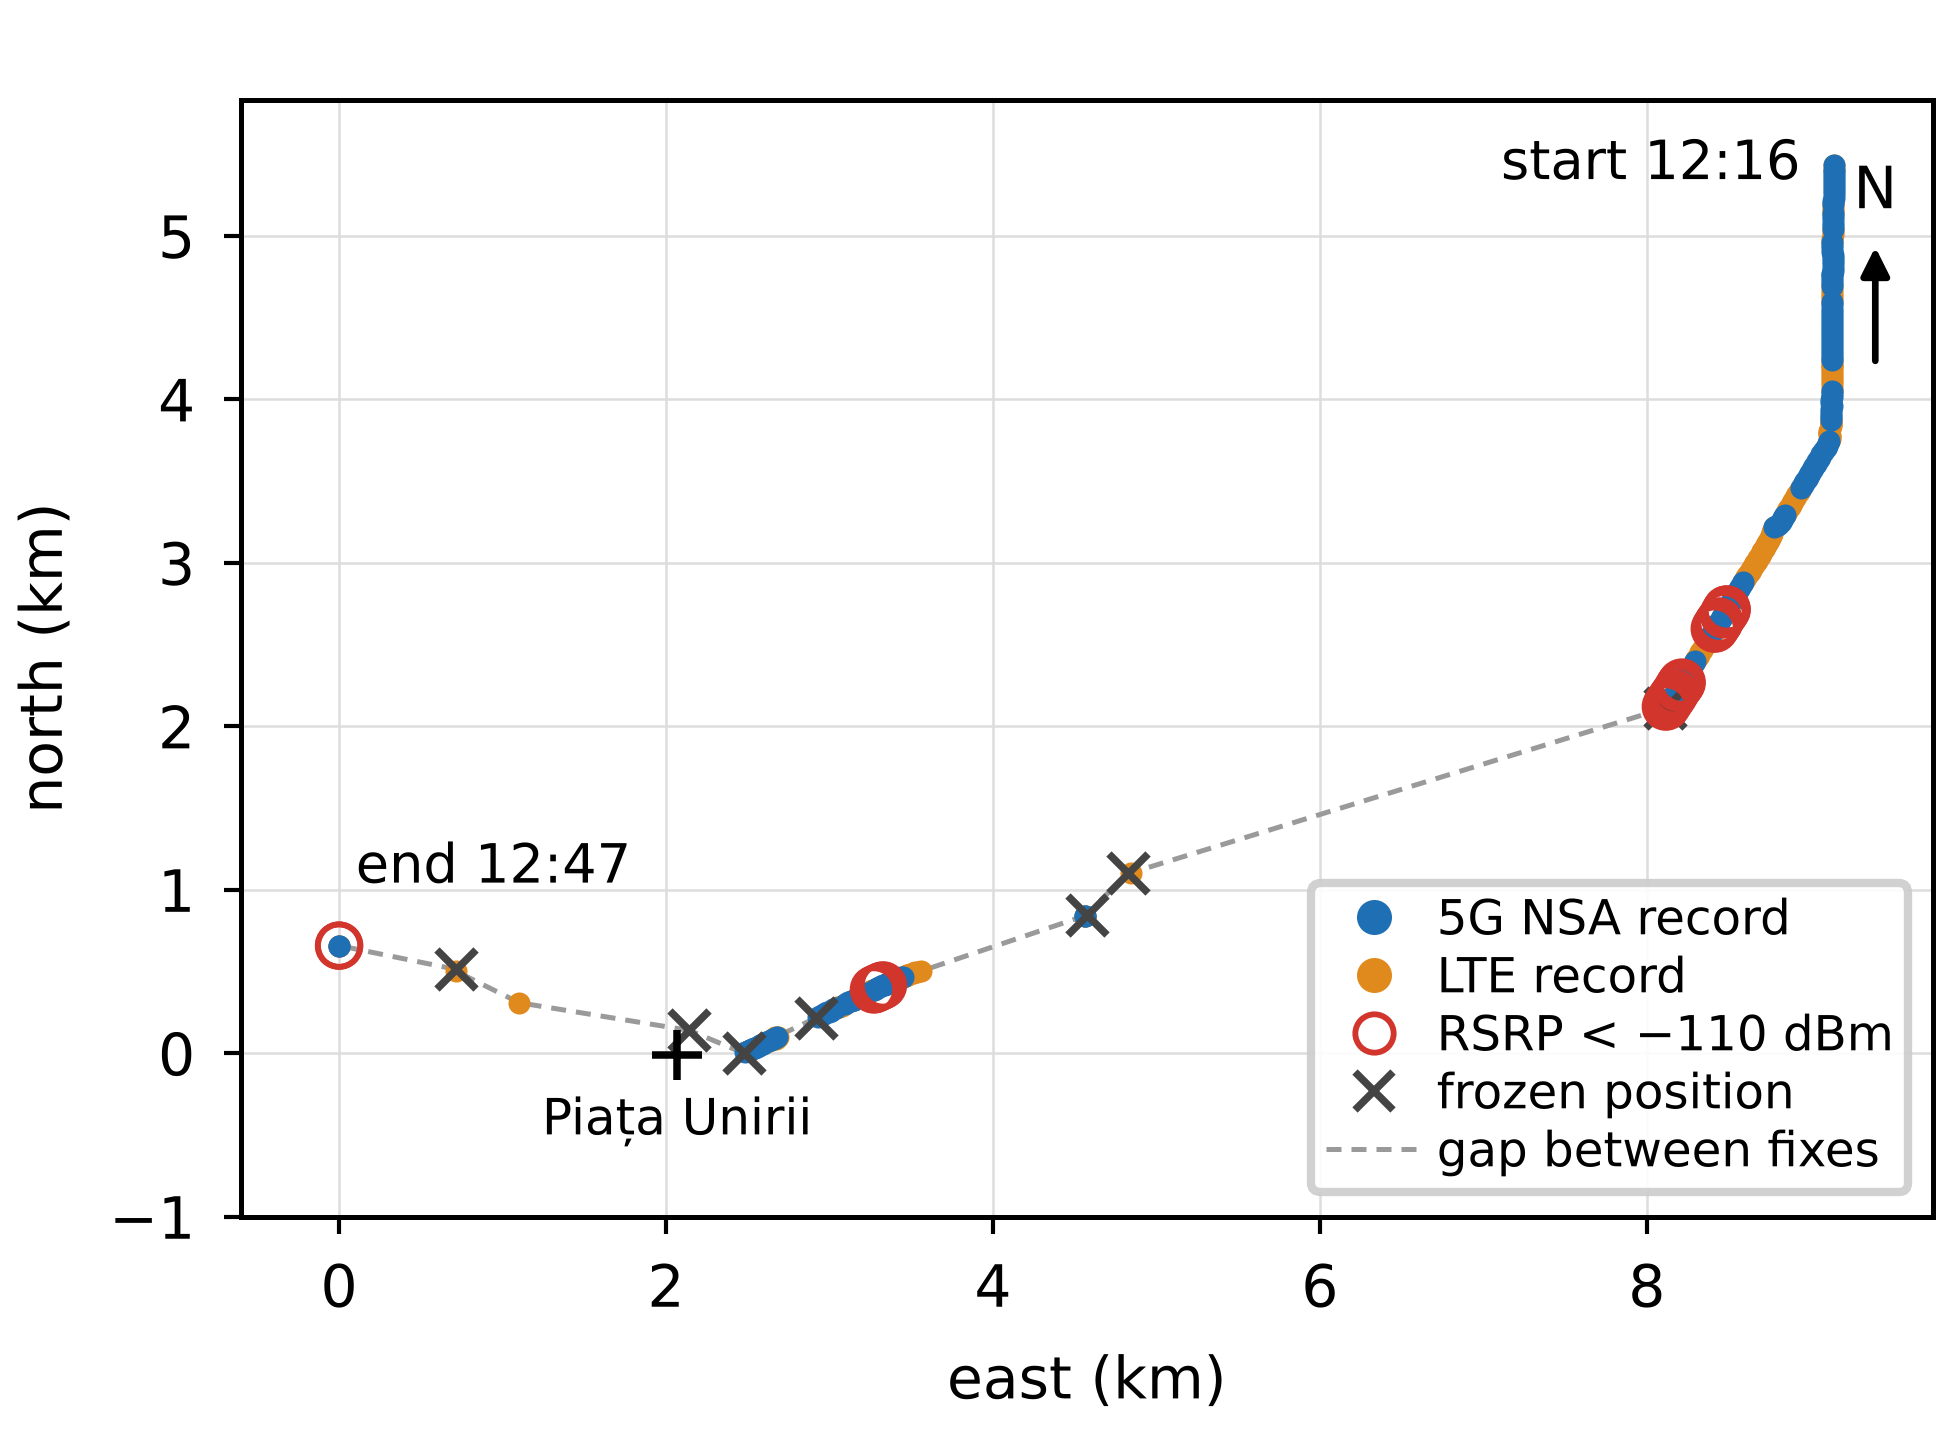

In [5]:
fig = ag.plot_route_map(d)
save_and_show(fig, "fig_route_map.png")

## Fig. 4 — time series

RSRP and SINR against time since the start of the log, with the serving PLMN, the RAT label and the mobility events.
Red and green lines are the poor and good thresholds of Table I.

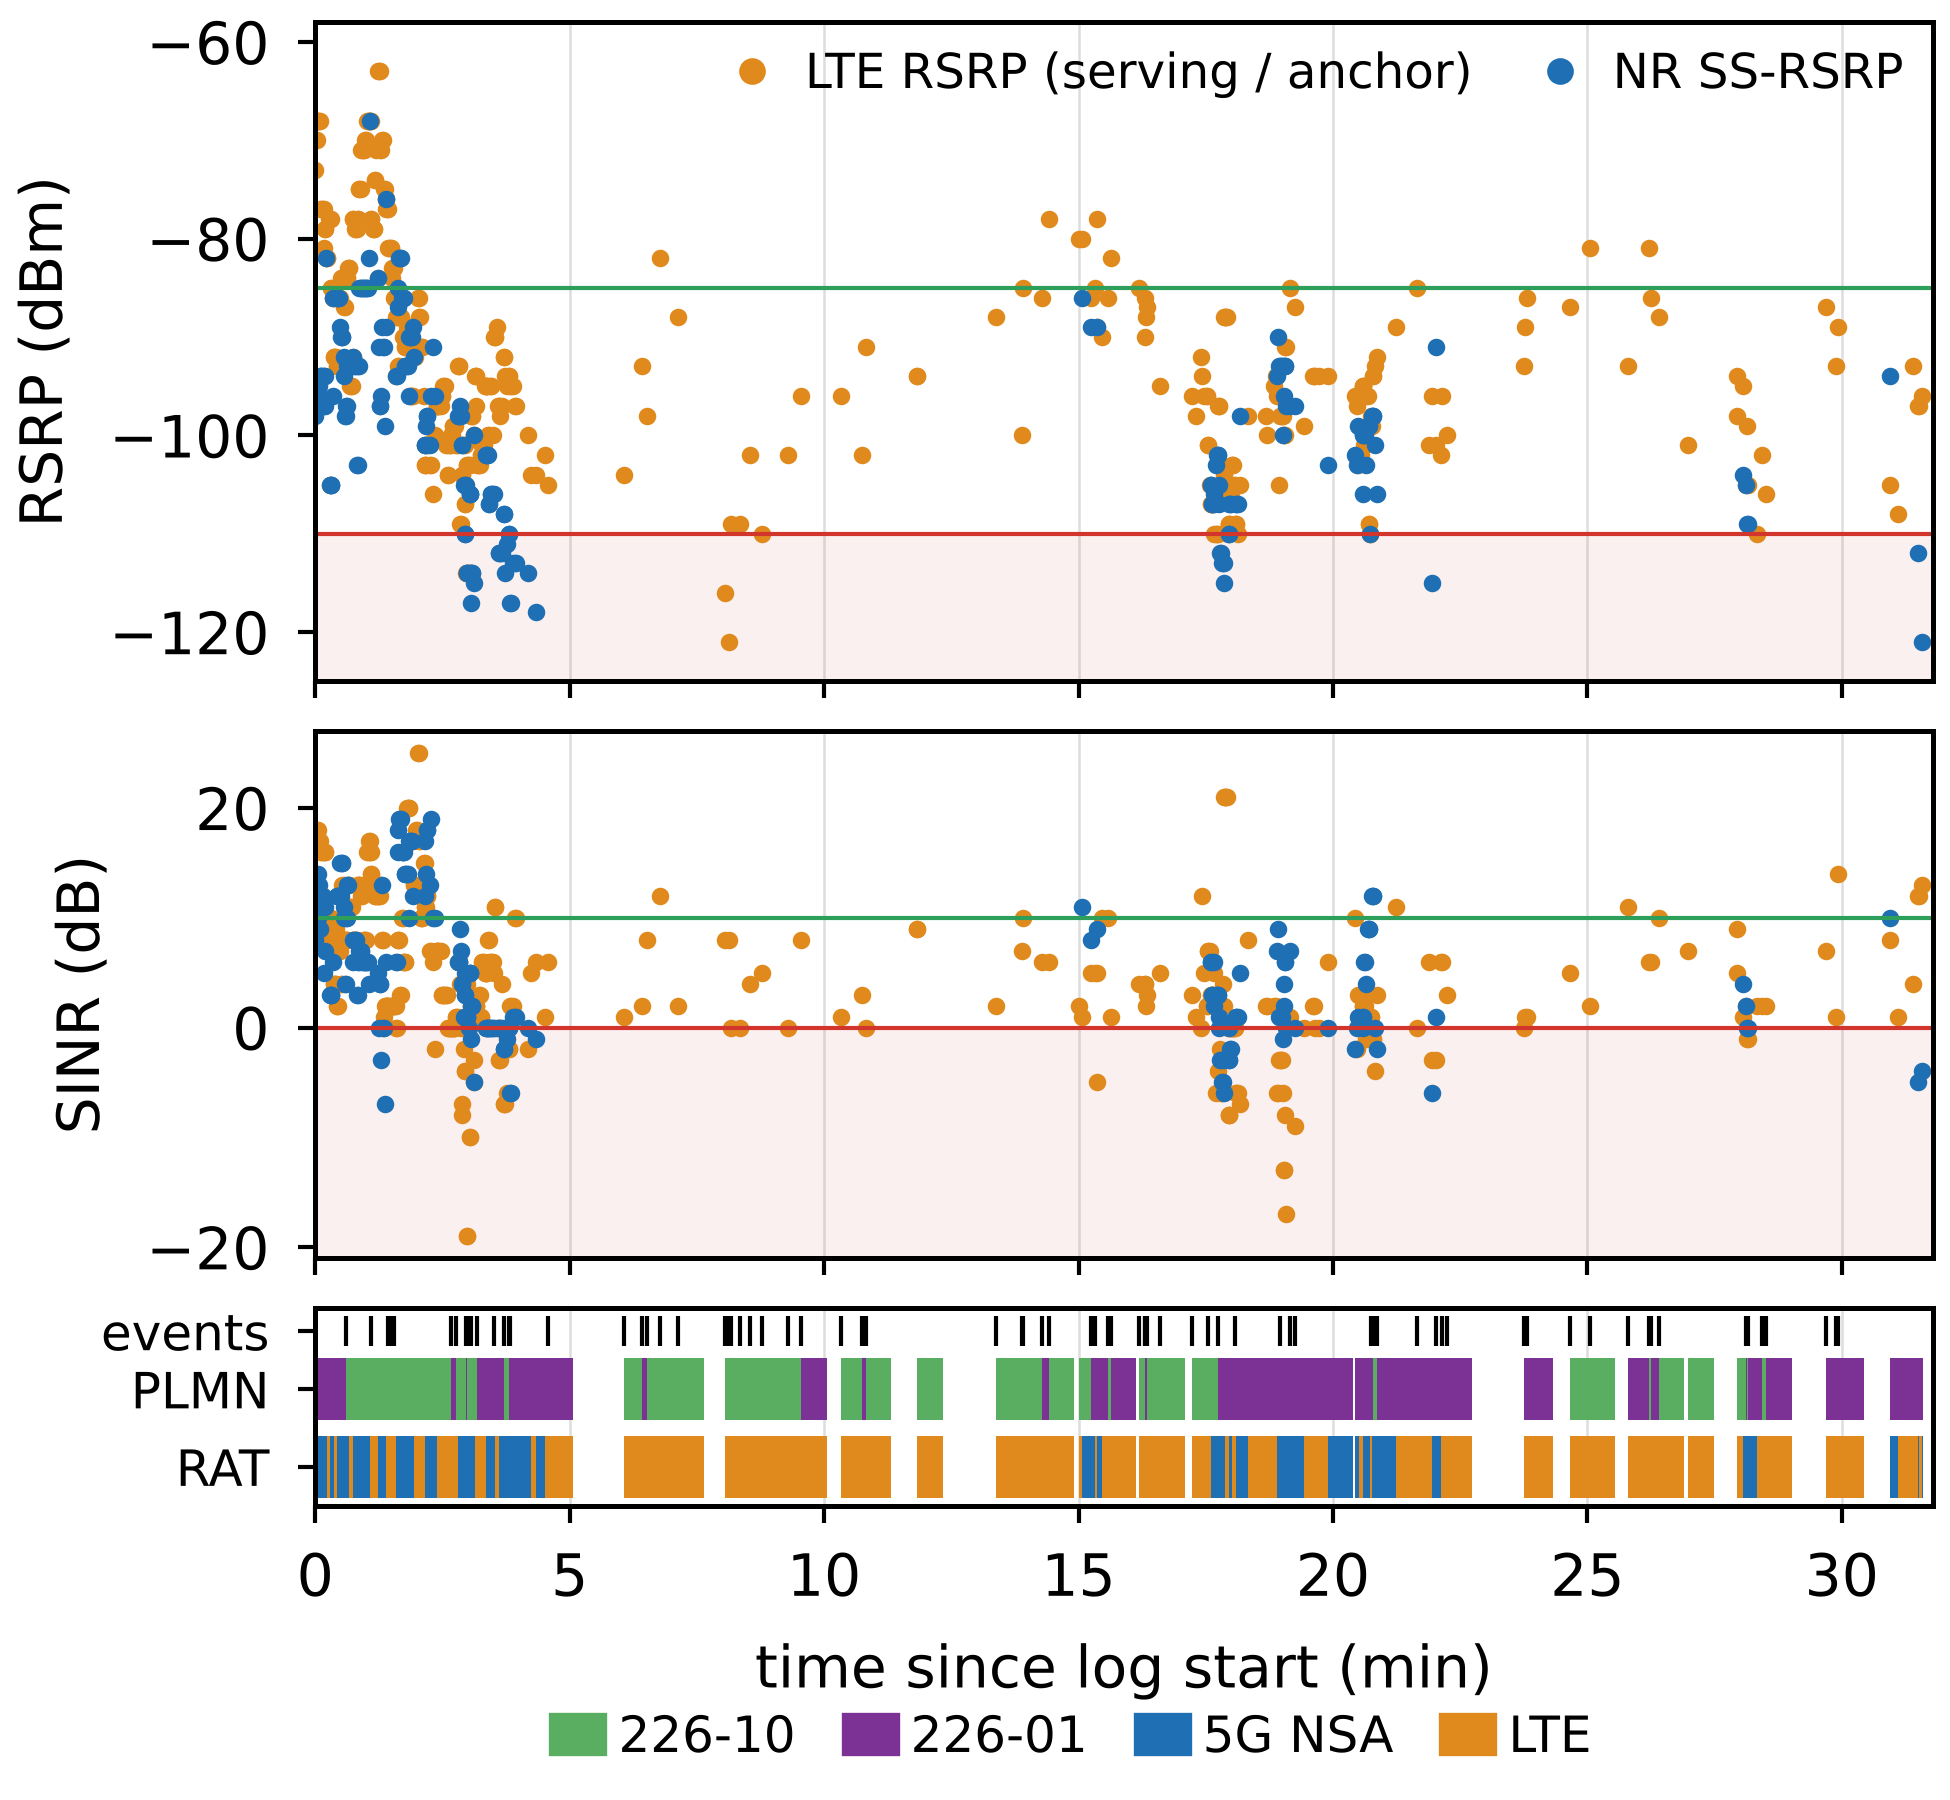

In [6]:
fig = ag.plot_timeseries(d, ev)
save_and_show(fig, "fig_timeseries.png")

## Distributions (supporting view of Table II)

Empirical CDFs of the per-record values; the shaded band is the poor range of Table I.

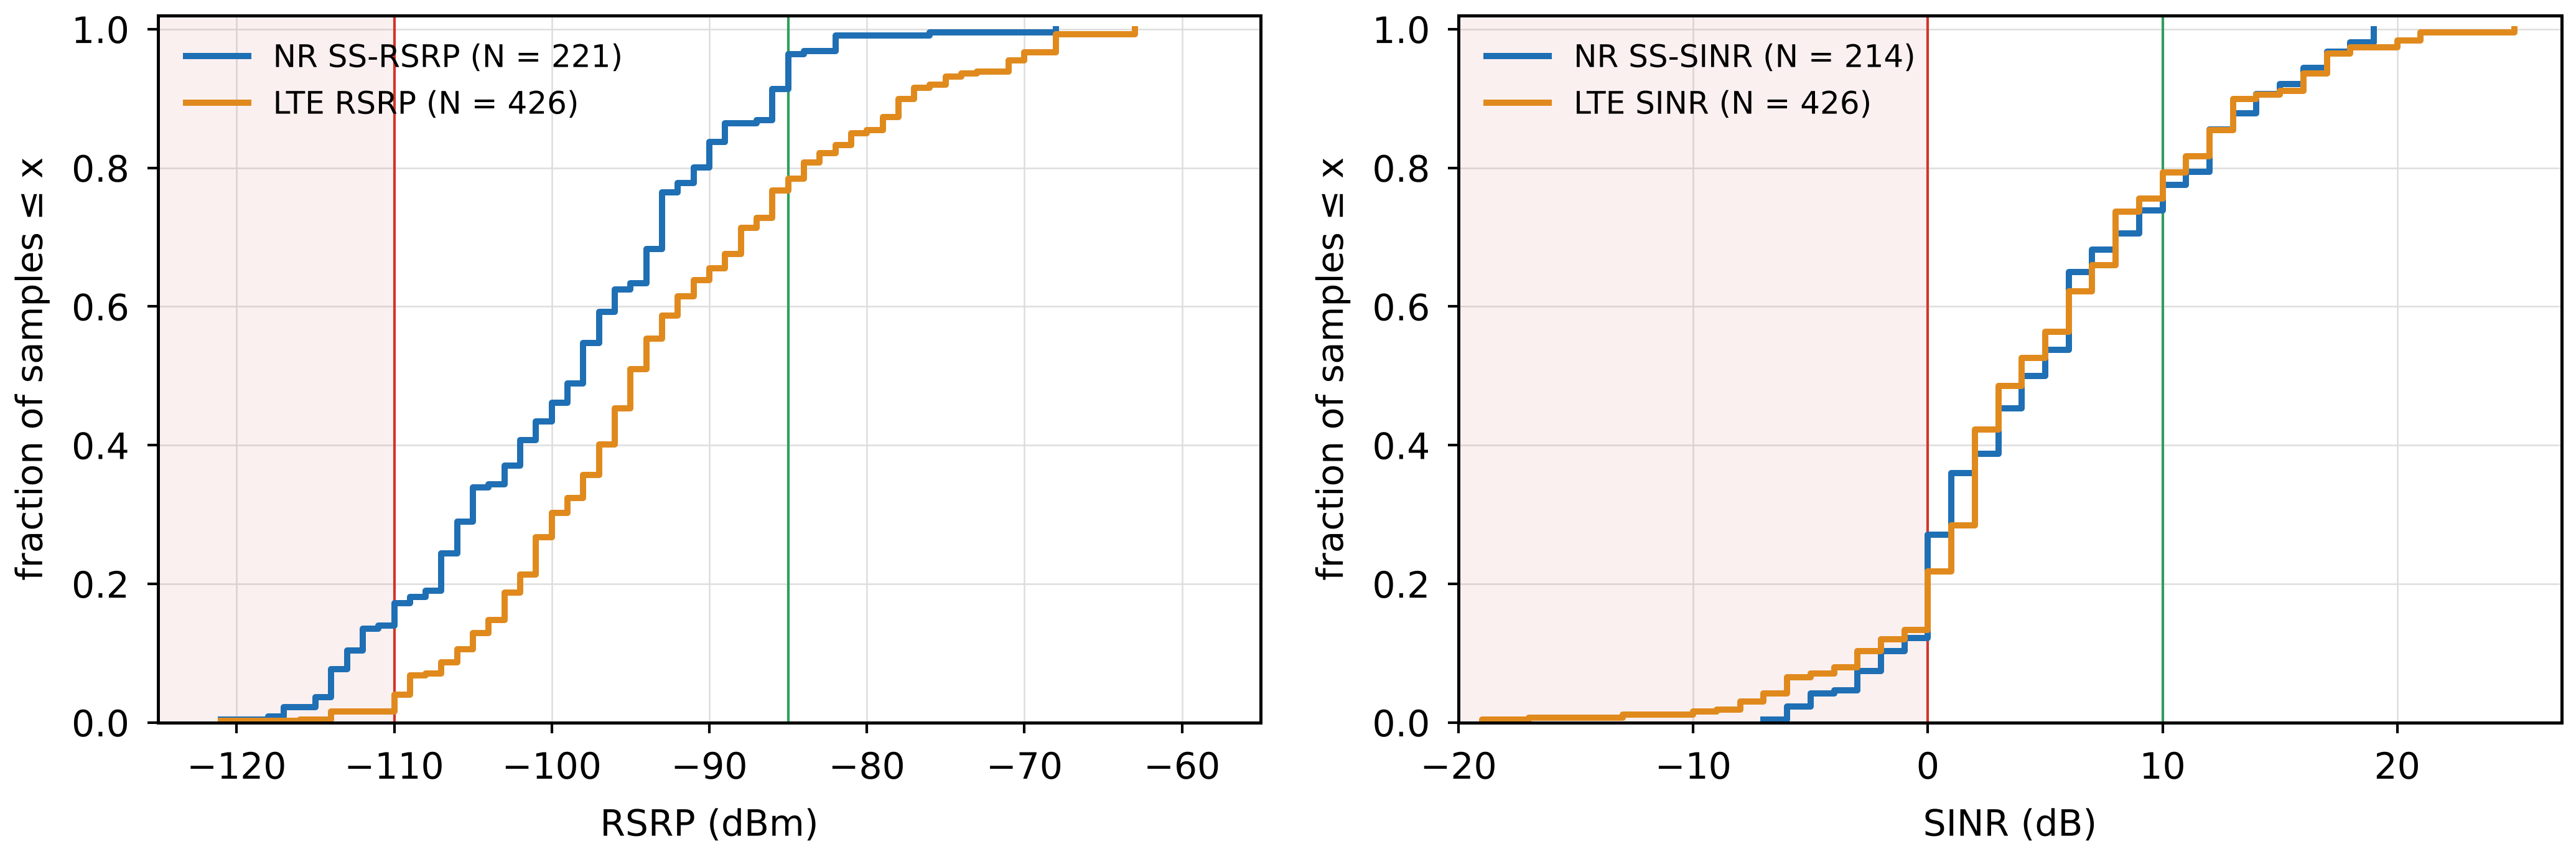

In [7]:
ag.set_style()
fig, axs = plt.subplots(1, 2, figsize=(6.9, 2.3))
panels = [(axs[0], "RSRP (dBm)", [("NR_RSRP", "NR SS-RSRP", ag.C_NR), ("LTE_RSRP", "LTE RSRP", ag.C_LTE)],
           ag.RSRP_POOR, ag.RSRP_GOOD, (-125, -55)),
          (axs[1], "SINR (dB)", [("NR_SINR", "NR SS-SINR", ag.C_NR), ("LTE_SINR", "LTE SINR", ag.C_LTE)],
           ag.SINR_POOR, ag.SINR_GOOD, (-20, 27))]
for ax, xlabel, series, poor, good, xlim in panels:
    ax.axvspan(xlim[0], poor, color=ag.C_POOR, alpha=0.07, lw=0)
    ax.axvline(poor, lw=0.5, color=ag.C_POOR)
    ax.axvline(good, lw=0.5, color=ag.C_GOOD)
    for col, label, colour in series:
        v = np.sort(d[col].dropna().values)
        ax.step(v, np.arange(1, v.size + 1) / v.size, where="post", lw=1.2, color=colour,
                label=f"{label} (N = {v.size})")
    ax.set_xlim(*xlim); ax.set_ylim(0, 1.02)
    ax.set_xlabel(xlabel); ax.set_ylabel("fraction of samples ≤ x")
    ax.grid(True, lw=0.3, color="#dddddd"); ax.set_axisbelow(True)
    ax.legend(loc="upper left", fontsize=6, frameon=False)
    ax.tick_params(length=2, width=0.5)
fig.tight_layout(pad=0.4, w_pad=1.5)
save_and_show(fig, "fig_ecdf.png", width=1000)

## Record shares versus time shares

G-NetTrack writes a record on distance, cell change or timer, so record counts are not time shares. Time weighting
credits each interval to the record that starts it; with the gap rule, intervals longer than 30 s are left out.

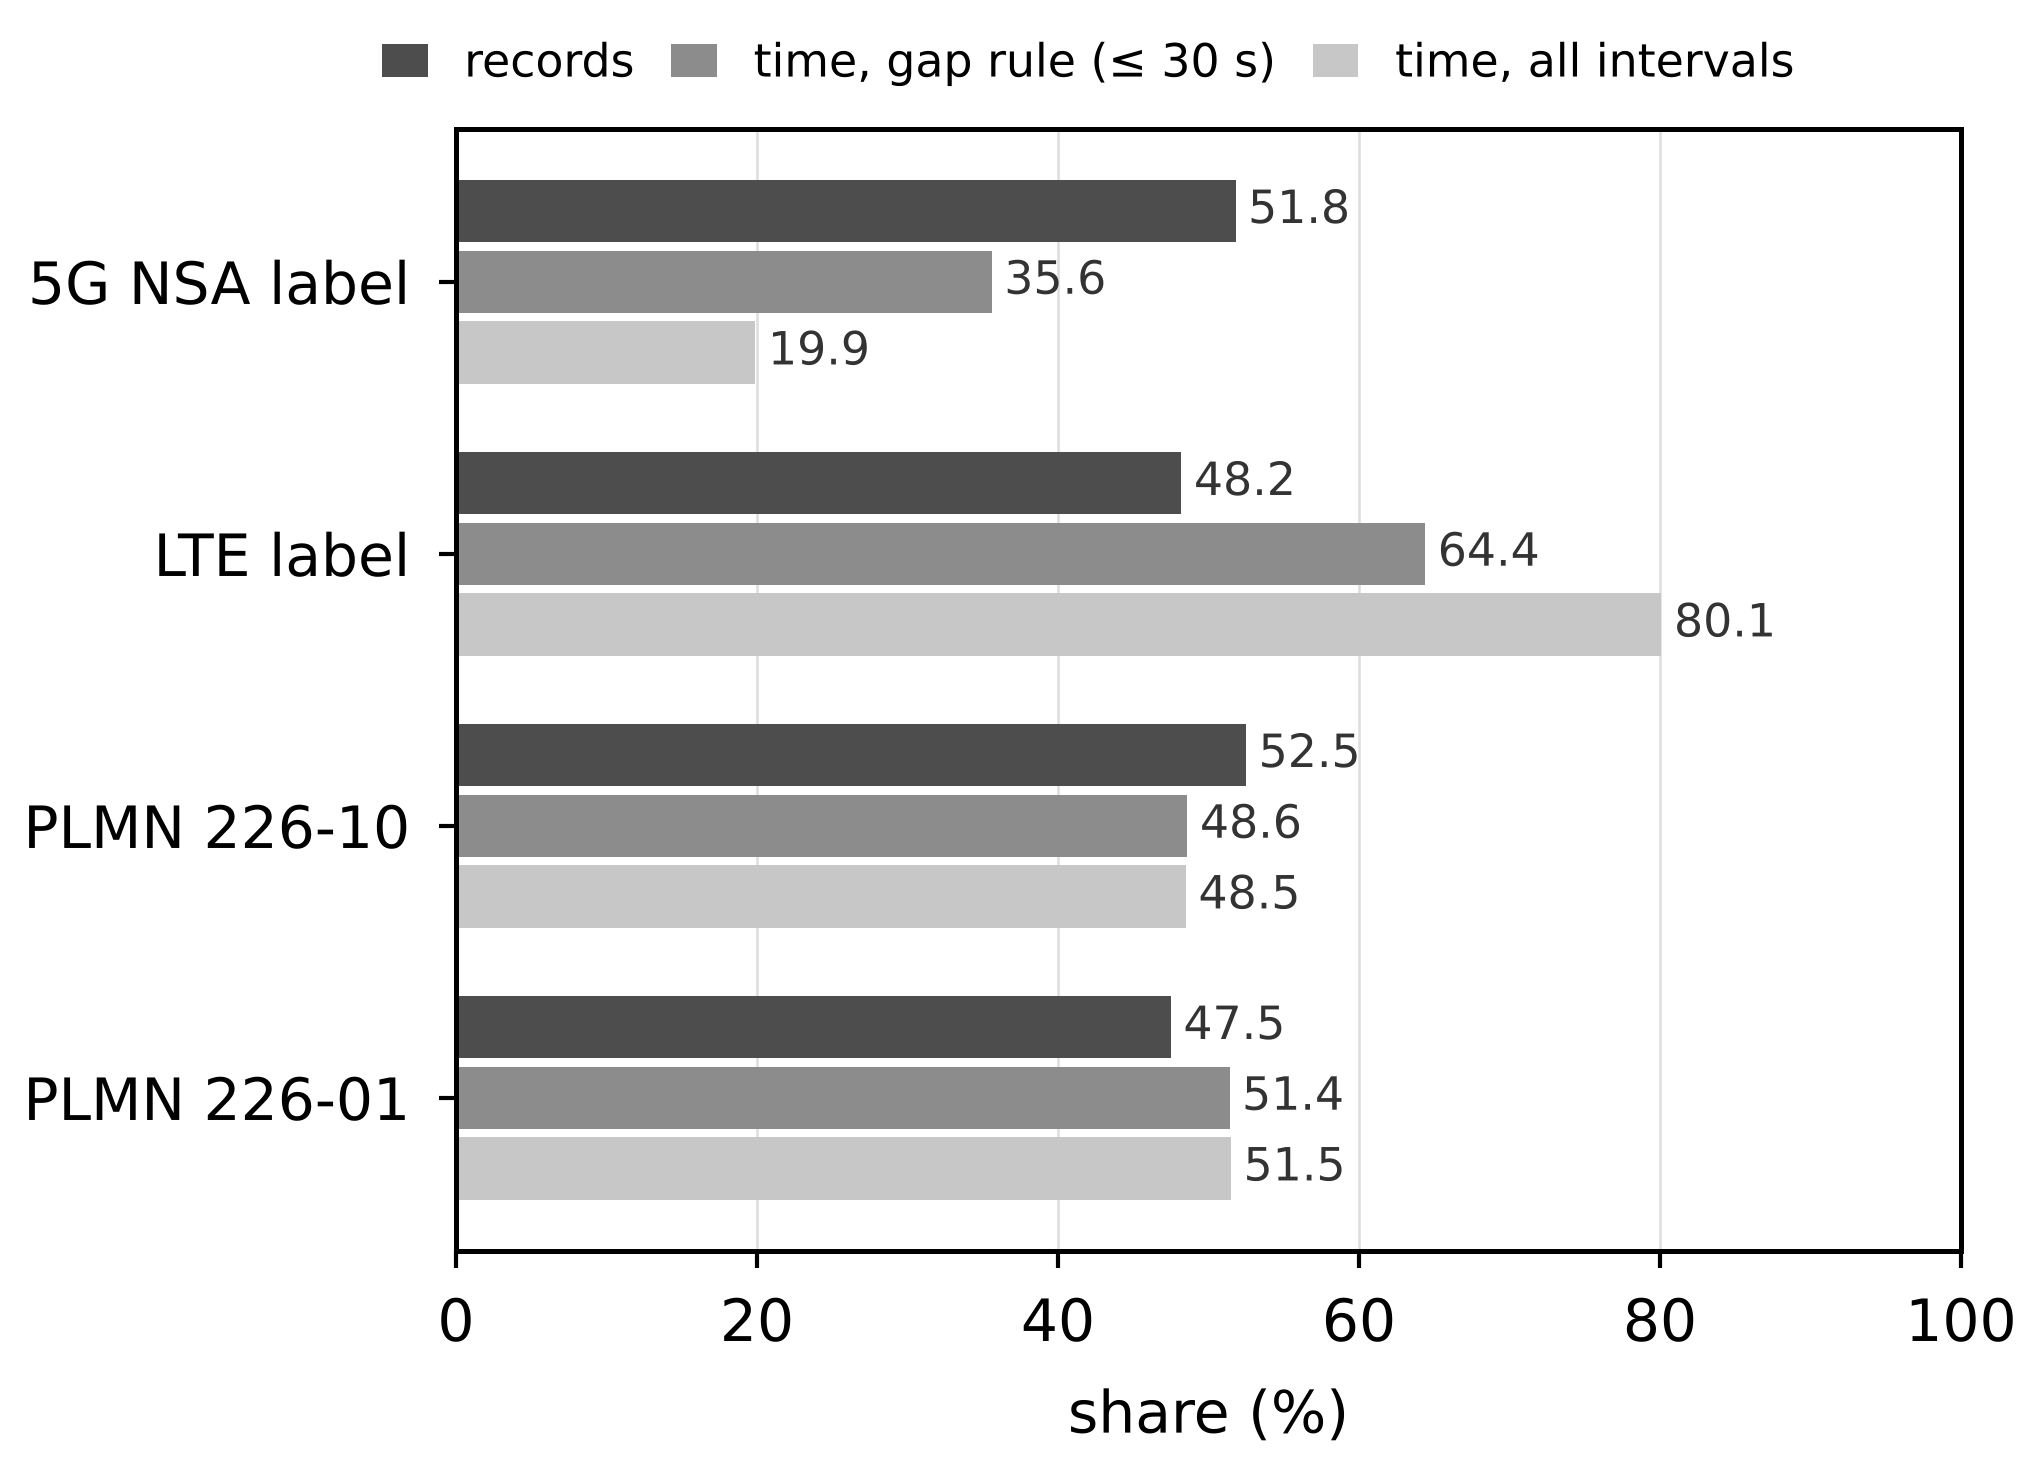

In [8]:
ag.set_style()
cats = [("5G NSA label", "rat_label", "5G"), ("LTE label", "rat_label", "4G"),
        ("PLMN 226-10", "serving_plmn", "22610"), ("PLMN 226-01", "serving_plmn", "22601")]
measures = [("records", "records_pct", "#4d4d4d"),
            ("time, gap rule (≤ 30 s)", "time_weighted_pct", "#8c8c8c"),
            ("time, all intervals", "time_weighted_no_gap_rule_pct", "#c7c7c7")]
fig, ax = plt.subplots(figsize=(3.4, 2.45))
y = np.arange(len(cats))
h = 0.26
for j, (label, key, colour) in enumerate(measures):
    vals = [shares[g][key].get(c, 0.0) for _, g, c in cats]
    bars = ax.barh(y + (j - 1) * h, vals, height=h - 0.03, color=colour, label=label)
    ax.bar_label(bars, fmt="%.1f", padding=1.5, fontsize=5.5, color="#333333")
ax.set_yticks(y, [c[0] for c in cats]); ax.invert_yaxis()
ax.set_xlim(0, 100); ax.set_xlabel("share (%)")
ax.grid(True, axis="x", lw=0.3, color="#dddddd"); ax.set_axisbelow(True)
ax.legend(loc="lower center", bbox_to_anchor=(0.42, 1.0), ncol=3, fontsize=5.5, frameon=False,
          handlelength=1.0, columnspacing=0.8)
ax.tick_params(length=2, width=0.5)
fig.tight_layout(pad=0.4)
save_and_show(fig, "fig_shares.png")

## Stage 4 screening — rules and Isolation Forest

5G-labelled records with all six radio values. The Isolation Forest (200 trees, contamination 0.05, `random_state=0`)
is used only to rank candidates for review; the flagged set changes with the seed.

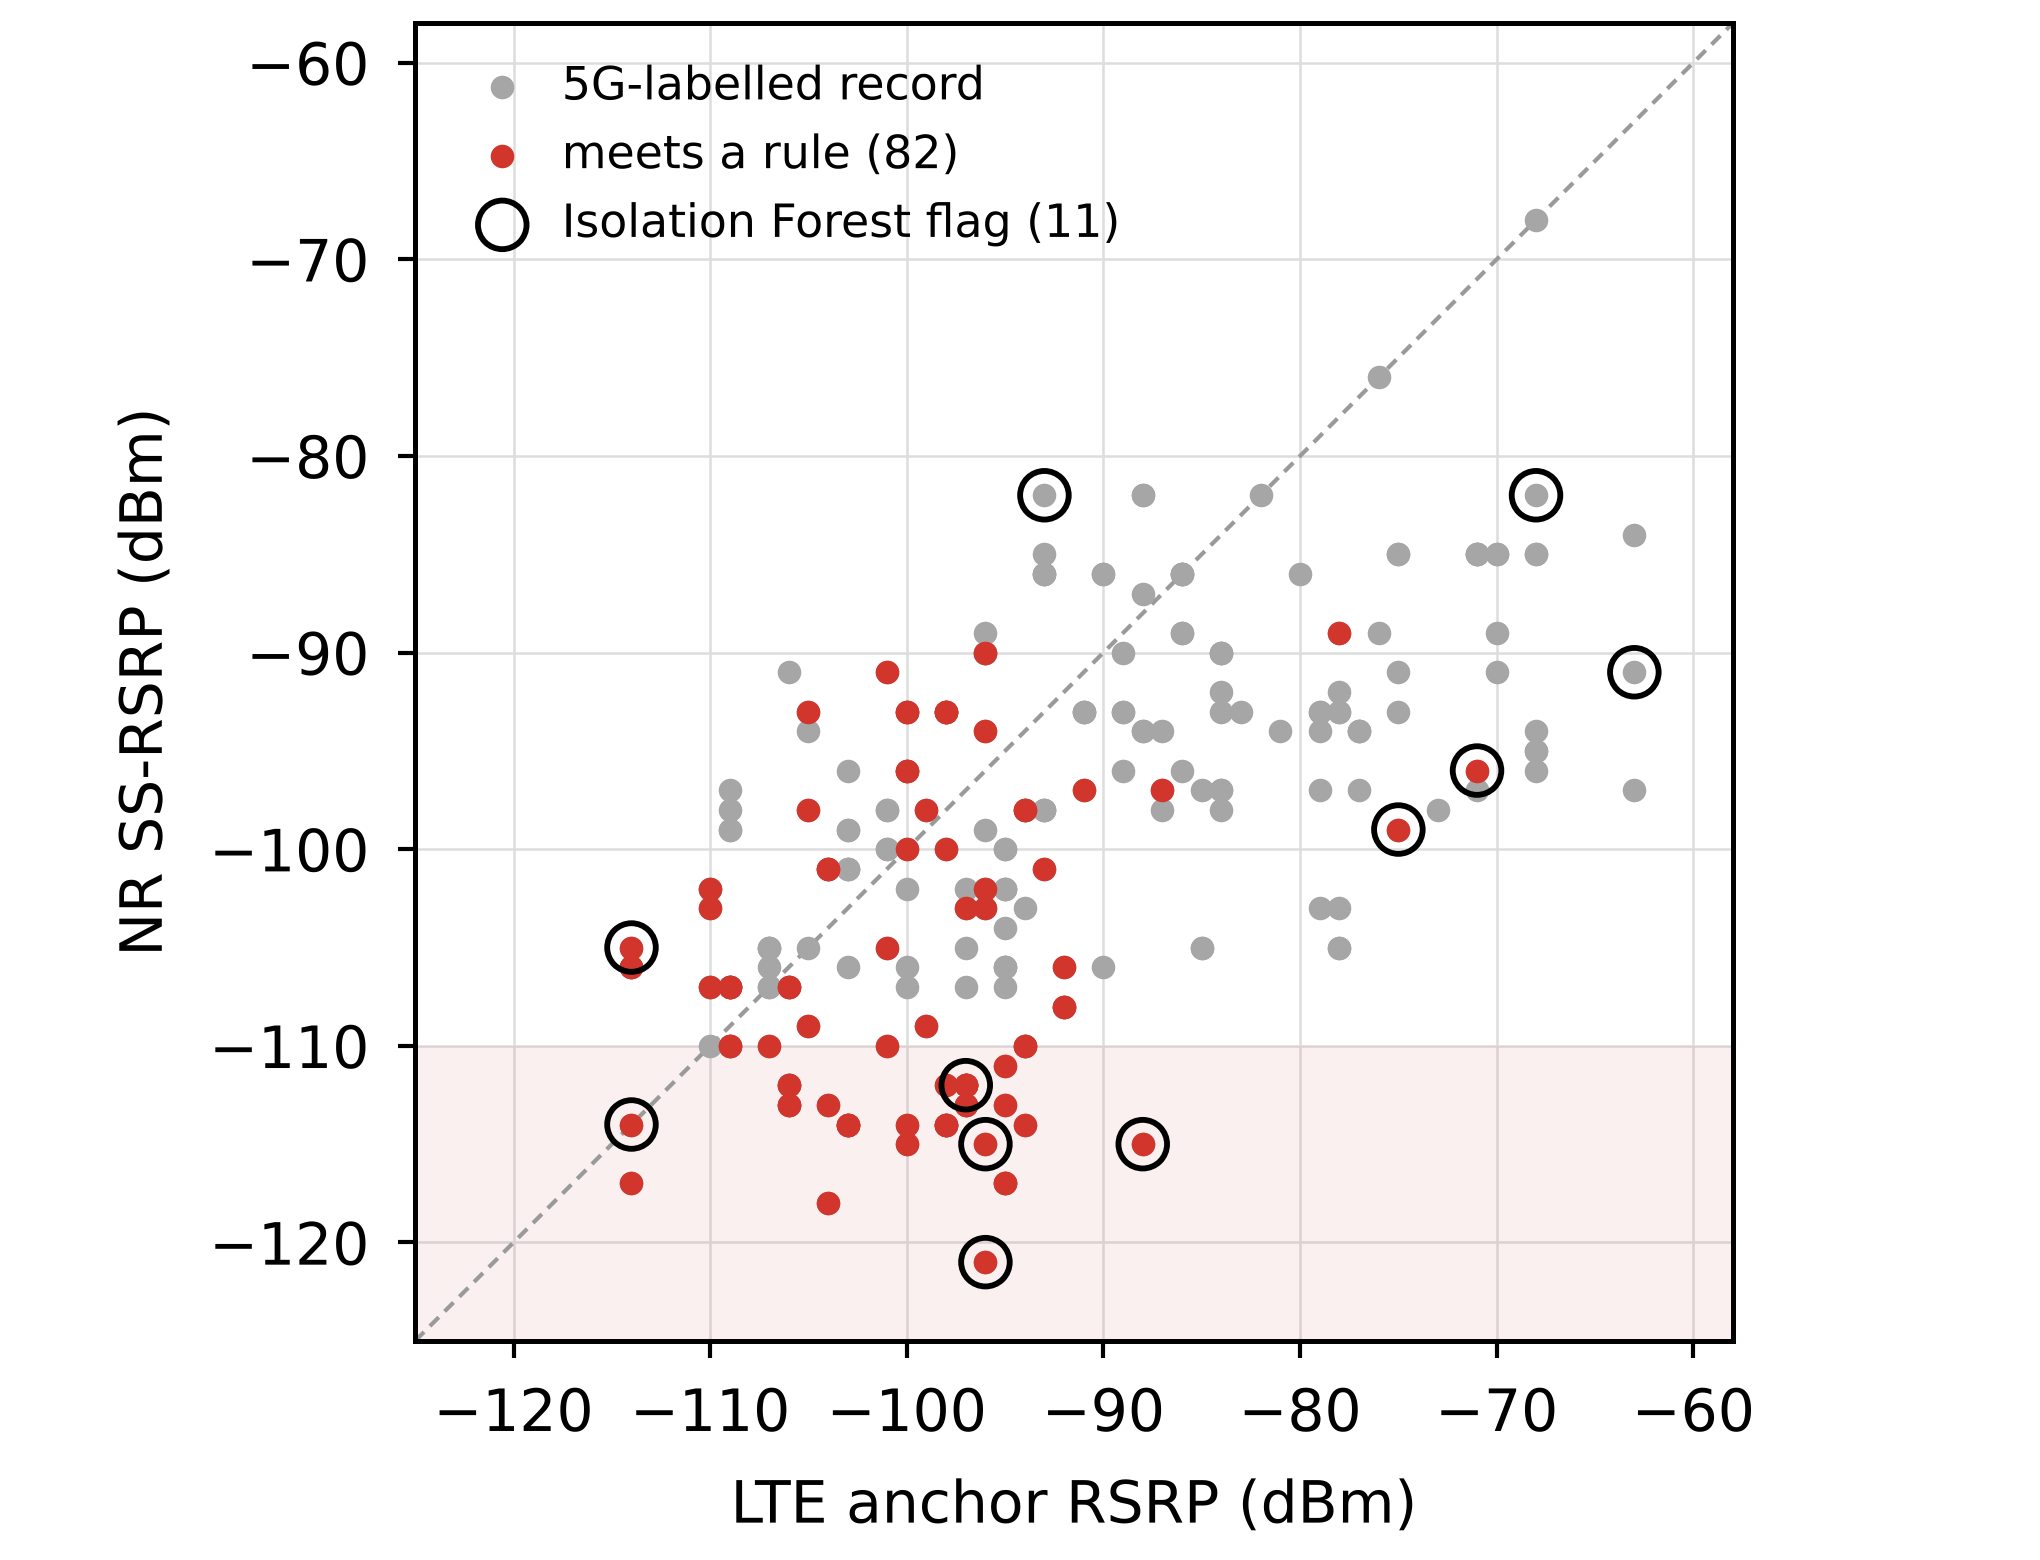

,value
records meeting a rule,84
poor RSRP on either layer,36
negative LTE-anchor SINR,57
negative NR SINR at non-poor NR RSRP,11
Isolation Forest: records used / flagged,214 / 11
flagged that also meet a rule,8
flagged under all 10 seeds / any seed,5 / 18


In [9]:
ag.set_style()
nsa = d[(d["NetworkTech"] == "5G")].dropna(subset=["NR_RSRP", "LTE_RSRP"])
fig, ax = plt.subplots(figsize=(3.4, 2.6))
lims = (-125, -58)
ax.plot(lims, lims, lw=0.5, color="#9a9a9a", ls=(0, (3, 2)))
ax.axhspan(lims[0], ag.RSRP_POOR, color=ag.C_POOR, alpha=0.07, lw=0)
ax.scatter(nsa["LTE_RSRP"], nsa["NR_RSRP"], s=8, color="#a6a6a6", lw=0, label="5G-labelled record", zorder=3)
r = nsa[nsa["_rule_any"].astype(bool)]
ax.scatter(r["LTE_RSRP"], r["NR_RSRP"], s=8, color=ag.C_POOR, lw=0, label=f"meets a rule ({len(r)})", zorder=4)
f = nsa[nsa["_if_flag"].astype(bool)]
ax.scatter(f["LTE_RSRP"], f["NR_RSRP"], s=34, facecolors="none", edgecolors="k", lw=0.7,
           label=f'Isolation Forest flag ({scr["iforest"]["flagged_n"]})', zorder=5)
ax.set_xlim(*lims); ax.set_ylim(*lims); ax.set_aspect("equal")
ax.set_xlabel("LTE anchor RSRP (dBm)"); ax.set_ylabel("NR SS-RSRP (dBm)")
ax.grid(True, lw=0.3, color="#dddddd"); ax.set_axisbelow(True)
ax.legend(loc="upper left", fontsize=5.5, frameon=False, handletextpad=0.3)
ax.tick_params(length=2, width=0.5)
fig.tight_layout(pad=0.4)
save_and_show(fig, "fig_screening.png")

pd.Series({
    "records meeting a rule": scr["rule_any_n"],
    "  poor RSRP on either layer": scr["rule_poor_coverage_any_layer_n"],
    "  negative LTE-anchor SINR": scr["rule_poor_LTE_anchor_SINR_n"],
    "  negative NR SINR at non-poor NR RSRP": scr["rule_notpoorRSRP_poorSINR_NR_n"],
    "Isolation Forest: records used / flagged": f'{scr["iforest"]["records_used"]} / {scr["iforest"]["flagged_n"]}',
    "  flagged that also meet a rule": scr["iforest"]["flagged_also_rule_n"],
    "  flagged under all 10 seeds / any seed": "{flagged_in_all} / {flagged_in_any}".format(**scr["iforest"]["seed_sensitivity_10_seeds"]),
}, name="value").to_frame()

## Table III — Stage 1 on the supplementary logs

The five supplementary logs are used only to test the reader and the Stage 1 checks on other handsets, networks and
technologies; no performance statement is made about those networks.

In [10]:
PLACE = {"Logs5G_RO-HU_BorderCrossing": "RO–HU border", "Logs_5G_XR30_Dublin": "Dublin",
         "Logs_LTE_S22_Barca": "Barcelona", "Logs_LTE_Gdansk": "Gdańsk"}
rows3 = []
for p in SUPP_LOGS:
    dfs = ag.load(p); ds = ag.prepare(dfs); a = ag.audit(dfs, ds)
    flags = []
    if a["timestamp_backward_steps"]:
        flags.append(f'clock steps back {-a["largest_backward_step_s"]:g} s')
    if a["rows_longer_than_header"]:
        n = a["rows_longer_than_header"]
        flags.append(f'{n} row{"s" * (n != 1)} longer than header')
    if a["operator_code_invalid_n"]:
        flags.append(f'{a["operator_code_invalid_n"]} placeholder operator codes')
    if a["level_out_of_range_n"]:
        flags.append(f'level {", ".join(f"{x} dBm" for x in a["level_out_of_range_values"])} in {a["level_out_of_range_n"]} records')
    if a["snr_missing_marker_n"]:
        flags.append(f'SNR missing in {a["snr_missing_marker_n"]}')
    if a["stale_position_records"]:
        flags.append(f'{a["stale_position_records"]} records on stale positions')
    if a["position_discontinuities_gt100m"]:
        n = a["position_discontinuities_gt100m"]
        flags.append(f'{n} position jump{"s" * (n != 1)} > 100 m')
    if a["active_test_rows"]:
        flags.append("active test rows: " + ", ".join(f"{k} {v}" for k, v in a["active_test_rows"].items()))
    rows3.append({
        "log": f'{PLACE.get(p.parent.name, p.parent.name)}, {pd.to_datetime(a["first_timestamp"], format="%Y.%m.%d_%H.%M.%S"):%d %b}',
        "handset": ", ".join(x.split(":")[1] for x in a["device"]),
        "records; RAT labels": f'{a["records"]}; ' + "/".join(sorted(a["rat_labels"])),
        "flagged by Stage 1": "; ".join(flags),
    })
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(rows3).set_index("log").sort_index(key=lambda ix: pd.to_datetime(ix.str[-6:] + " 2026", format="%d %b %Y")))

,handset,records; RAT labels,flagged by Stage 1
log,,,
"RO–HU border, 09 Jun",Nokia X30 5G,2365; 2G/4G/5G,"clock steps back 3599 s; 89 rows longer than header; 5 placeholder operator codes; SNR missing in 166; active test rows: PING 22, UPLOAD 21, DOWNLOAD 21"
"Dublin, 12 Jun",Nokia X30 5G,108; 3G/4G/5G,"clock steps back 3586 s; level -200 dBm in 2 records; SNR missing in 57; active test rows: PING 13, UPLOAD 12, DOWNLOAD 11, VOICE SEQUENCE 9"
"Barcelona, 12 Jul",SM-S901B,59; 4G,1 row longer than header; 12 records on stale positions; 1 position jump > 100 m
"Gdańsk, 26 Jul",SM-S901B,95; 4G,level -340 dBm in 3 records; 93 records on stale positions; 1 position jump > 100 m
"Gdańsk, 27 Jul",SM-S901B,152; 4G,57 records on stale positions; 4 position jumps > 100 m


## LLM stage — agreement with the reference

Summary of `results/llm_stage_verification.json`, written by `src/verify_llm_stage.py`: the three independent runs
of the fixed prompt (Fig. 2 of the paper) compared with the reference statistics, and the narrative figures
re-computed with separate code.

In [11]:
v = json.load(open(RESULTS_DIR / "llm_stage_verification.json", encoding="utf-8"))
display(pd.DataFrame({run: {"Table II values equal": f'{x["table2_values_equal"]} / {x["table2_values_compared"]}',
                            "counts equal": f'{x["counts_equal"]} / {x["counts_compared"]}',
                            "wall-clock time (s)": x["wall_clock_s"],
                            "narrative words": x["narrative_words"]} for run, x in v["runs"].items()}))
print(f'narrative figures re-computed: {v["narrative_claims_reproduced"]} of {v["narrative_claims_checked"]} reproduced')

,run1,run2,run3
Table II values equal,40 / 40,40 / 40,40 / 40
counts equal,18 / 18,18 / 18,18 / 18
wall-clock time (s),698,635,506
narrative words,396,396,398


narrative figures re-computed: 91 of 91 reproduced


In [12]:
print("figures written to", FIG_DIR.resolve().relative_to(Path('..').resolve()))
for p in sorted(FIG_DIR.glob("*.png")):
    print(" ", p.name)

figures written to results/figures
  fig_ecdf.png
  fig_route_map.png
  fig_screening.png
  fig_shares.png
  fig_timeseries.png
